In [1]:
from collections import defaultdict
from pathlib import Path

import numpy as np

In [2]:
plots = Path("plots") / "compression"

In [3]:
from dataclasses import dataclass


@dataclass
class CompressionRatios:
    percentile: list[float]
    absolute: list[float]
    relative: list[float]
    quadratic: list[float]

In [4]:
def parse_single(path: Path):
    with Path(path).open() as f:
        for line in f:
            var, rest = line.split(": ", 1)
            info = eval(rest)

            yield var, info

In [5]:
def parse_pressure(path: Path):
    with Path(path).open() as f:
        ls = iter(f.readlines())

        line = None

        while True:
            if line is None:
                try:
                    line = next(ls)
                except StopIteration:
                    break

            var, rest = line.split(":", 1)

            while True:
                try:
                    line = next(ls)
                except StopIteration:
                    line = None
                    break

                if len(line.strip()) == 0:
                    continue

                if not line.startswith(" - "):
                    break

                level, rest = line[len(" - ") :].split(": ", 1)
                info = eval(rest)

                yield var, level, info

In [6]:
compression_ratios_single = dict(parse_single("compression-ratio-single.txt"))

In [7]:
compression_ratios_pressure = defaultdict(dict)
for v, p, c in parse_pressure("compression-ratio-pressure.txt"):
    compression_ratios_pressure[p][v] = c
compression_ratios_pressure = {k: v for k, v in compression_ratios_pressure.items()}

In [8]:
import matplotlib
from matplotlib import pyplot as plt
from matplotlib import ticker as mtick

In [9]:
tab20c = matplotlib.colormaps["tab20c"].colors

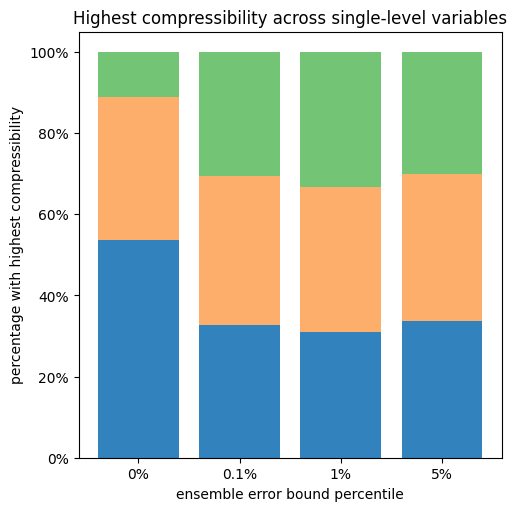

In [10]:
fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")

percentiles = compression_ratios_single["u10"].percentile
kinds = ["absolute", "relative", "quadratic"]
colours = [tab20c[0], tab20c[4 + 2], tab20c[8 + 1]]

for i, percentile in enumerate(percentiles):
    base = 0

    for j, (kind, c) in enumerate(zip(kinds, colours)):
        count = 0
        for v, cr in compression_ratios_single.items():
            count += np.argmax([getattr(cr, k)[i] for k in kinds]) == j

        ax.bar(
            i,
            count / len(compression_ratios_single),
            bottom=base / len(compression_ratios_single),
            color=c,
        )

        base += count

ax.set_title("Highest compressibility across single-level variables")
ax.set_xticks(range(len(percentiles)))
ax.set_xticklabels(
    [
        f"{np.format_float_positional((1 - p) * 100, trim='-', precision=1)}%"
        for p in percentiles
    ]
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))

ax.set_xlabel("ensemble error bound percentile")
ax.set_ylabel("percentage with highest compressibility")

plt.show()
fig.savefig(plots / "single.pdf")

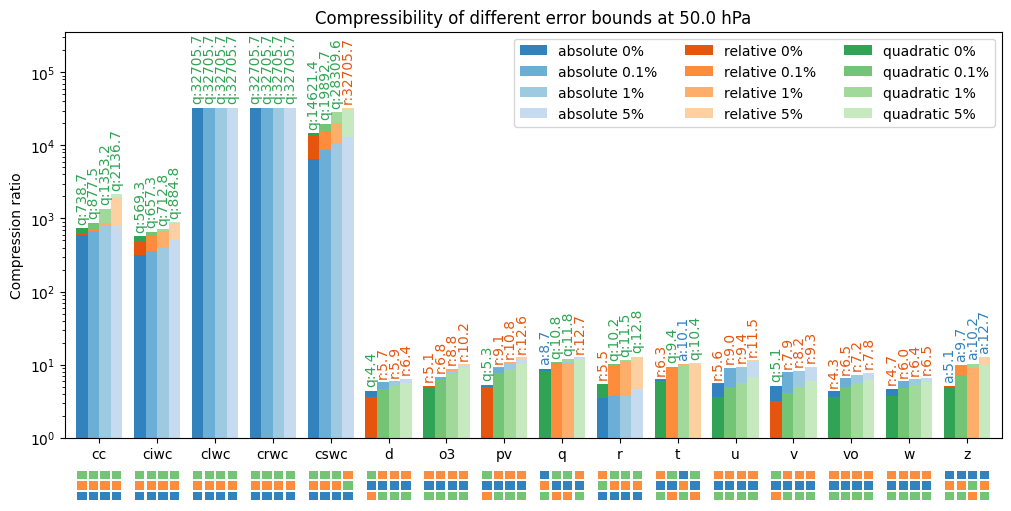

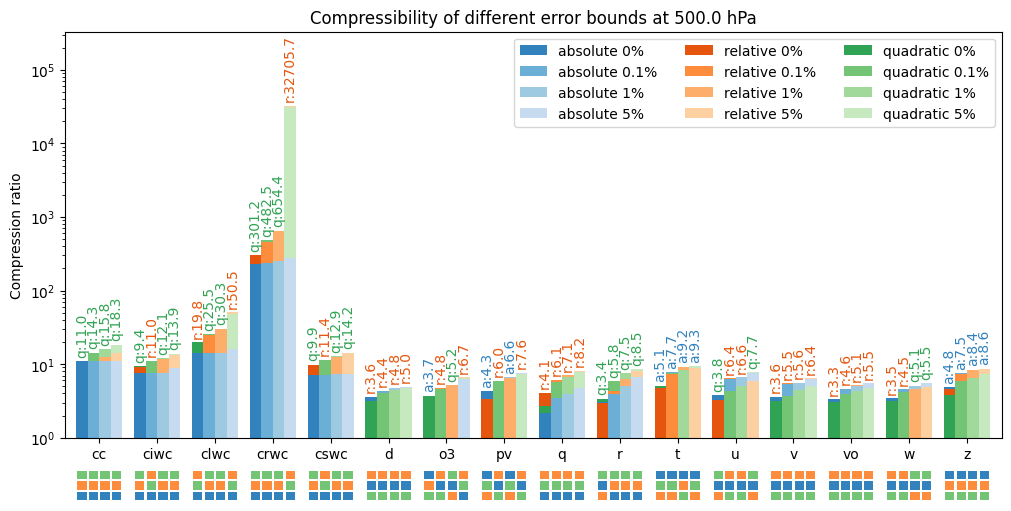

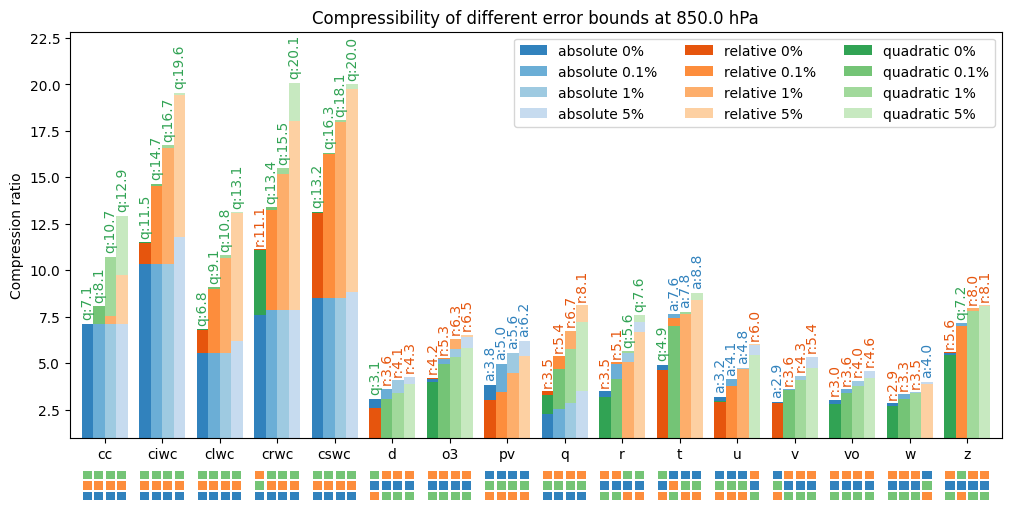

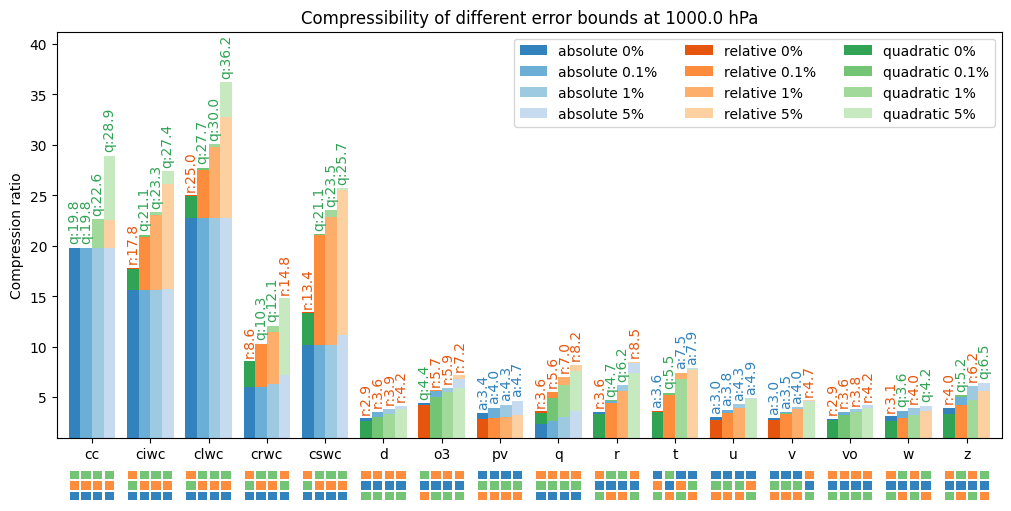

In [11]:
percentiles = compression_ratios_pressure["1000.0 hPa"]["u"].percentile
variables = compression_ratios_pressure["1000.0 hPa"]

x = np.arange(len(variables))
width = 0.2

for level in compression_ratios_pressure:
    fig, (ax, axt) = plt.subplots(
        2,
        1,
        figsize=(10, 5),
        layout="constrained",
        height_ratios=(13, 1),
        gridspec_kw=dict(hspace=0),
    )

    abs_handles = []
    rel_handles = []
    qua_handles = []

    multiplier = -0.5
    for j, p in enumerate(percentiles):
        offset = width * multiplier

        cr_abs = [
            compression_ratios_pressure[level][var].absolute[j] for var in variables
        ]
        cr_rel = [
            compression_ratios_pressure[level][var].relative[j] for var in variables
        ]
        cr_qua = [
            compression_ratios_pressure[level][var].quadratic[j] for var in variables
        ]

        cr_all = np.array(
            [
                [1.0, a, r, q, max(a, r, q) * 10]
                for a, r, q in zip(cr_abs, cr_rel, cr_qua)
            ]
        )
        assert np.all(cr_all >= 1.0)
        cr_sor = np.sort(cr_all, axis=1)
        cr_idx = np.argsort(cr_all, axis=1)

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 1])],
            width,
            label=f"absolute {np.format_float_positional((1 - p) * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 1])],
            color=tab20c[0 + j],
        )
        abs_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"a:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 1])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[0],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 1] - 0.9,
            color=tab20c[0],
        )

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 2])],
            width,
            label=f"relative {np.format_float_positional((1 - p) * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 2])],
            color=tab20c[4 + j],
        )
        rel_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"r:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 2])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[4],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 2] - 0.9,
            color=tab20c[4 + 1],
        )

        rects = ax.bar(
            x + offset,
            [csor[i] - csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 3])],
            width,
            label=f"quadratic {np.format_float_positional((1 - p) * 100, trim='-', precision=1)}%",
            bottom=[csor[i - 1] for csor, i in zip(cr_sor, cr_idx[:, 3])],
            color=tab20c[8 + j],
        )
        qua_handles.append(rects)
        ax.bar_label(
            rects,
            labels=[
                f"q:{np.round(csor[i], 1)}" if i == (cr_idx.shape[1] - 2) else ""
                for csor, i in zip(cr_sor, cr_idx[:, 3])
            ],
            padding=3,
            rotation="vertical",
            color=tab20c[8],
        )

        axt.bar(
            x + offset,
            0.8,
            width * 0.8,
            bottom=cr_idx[:, 3] - 0.9,
            color=tab20c[8 + 1],
        )

        multiplier += 1

    if level in ["1000.0 hPa", "850.0 hPa"]:
        ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[1] * 1.085)
    else:
        ax.set_yscale("log")
        ax.set_ylim(
            ax.get_ylim()[0], ax.get_ylim()[1] * (6.0 if level == "500.0 hPa" else 11.0)
        )

    ax.set_ylabel("Compression ratio")
    ax.set_title(f"Compressibility of different error bounds at {level}")
    ax.set_xticks(x + width, variables)
    ax.set_xlim(-0.4, len(variables) - 0.2)
    ax.legend(handles=abs_handles + rel_handles + qua_handles, ncol=3)

    axt.set_xlim(-0.4, len(variables) - 0.2)
    axt.set_ylim(0, 3)
    axt.set_xticks([])
    axt.set_yticks([])
    axt.set_axis_off()

    plt.show()
    fig.savefig(plots / f"pressure-{level.replace(' ', '')}.pdf")